# 3. Direct change detection

aka the thing I spent entire days working on for the past 2 years.

So we've seen how to do it indirectly, now let's see how it's actually done.

We will use our [BTC (Be The Change)](https://arxiv.org/abs/2507.03367). Both images go through the encoder, features that we get are subtracted and the decoder predicts the change map. The idea is that similar concept cancel out, while actually different object produce large difference. Latent space is more robust to simple things like lighting and seasonal variations.

BTC was trained on [LEVIR-CD](https://justchenhao.github.io/LEVIR/): 637 pairs of 0.5 m images of US cities, focusing only on buidling changes.


In [27]:
from pathlib import Path

import geopandas as gpd
import kornia.augmentation as K
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from lightning import Trainer
from shapely.geometry import box
from torch import nn
from torch.utils.data import DataLoader

from torchgeo.datasets import IntersectionDataset, RasterDataset, Sentinel2
from torchgeo.models import DEO_Weights, deo_base
from torchgeo.samplers import GriddedPatchSampler, RandomPatchSampler
from torchgeo.tasks import ChangeDetection

PREPARED = Path('../data/prepared')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

train_roi = box(457250, 100000, 458250, 103000)
test_roi = box(458250, 100000, 458750, 103000)
val_roi = box(458750, 100000, 459500, 103000)

# Data

`ChangeDetection` task expects images in `[time, band, height, width]` and mask with channel acis. Our joined dataset stacks both in channel axis, so we weill need a reshape transform to handle this.

In [28]:
normalize = K.AugmentationSequential(K.Normalize(mean=0, std=255), data_keys=None, keepdim=True)

def as_pair(sample):
    """(2 * c, h, w) becomes (2, c, h, w), and (h, w) becomes (1, h, w) for the mask."""
    sample['image'] = sample['image'].unflatten(0, (2, -1))
    sample['mask'] = sample['mask'][None]
    return sample

class Mask(RasterDataset):
    is_image = False


before = RasterDataset(PREPARED / 'rgb/2018.tif', transforms=normalize)
after = RasterDataset(PREPARED / 'rgb/2024.tif', transforms=normalize)
change = Mask(PREPARED / 'labels/change.tif')
pair = IntersectionDataset(before & after, change, transforms=as_pair)

def grid_patches(dataset, roi, size):
    sampler = GriddedPatchSampler(dataset, size=size, roi=roi)
    return DataLoader(dataset, sampler=sampler, batch_size=2)

## BTC trained on LEVIR-CD

I trained BTC on LEVIR-CD with the `ChangeDetection` task. We test it on our test area, with the same F1 and IoU as in the previous notebook. In this case, we do not need to perform a "manual" teest loop as the task already covers that (so loop + metrics).

In [29]:
# this is a sort of workaround for adaptive avg pool not working on mac...
def pool_matrix(size, out, like):
    """(out, size) matrix with weight in each row representing window of adaptive pooling kernel"""
    position = torch.arange(size)
    i = torch.arange(out).view(-1, 1)  # (out, 1) one row per output cell
    # adaptive pooling calculates windows based on in size and req out size: wsz = size / out
    # flor and ciel handle the uneven size
    start = torch.floor(i * size / out)
    end = torch.ceil((i + 1) * size / out)
    # broadcasts to (out, size)
    in_window = (start <= position) & (position < end)
    return (in_window / in_window.sum(dim=1, keepdim=True)).to(like)  # 1 / window length

class MatmulAdaptiveAvgPool2d(nn.AdaptiveAvgPool2d):
    """AdaptiveAvgPool2d with two matmuls, so non-divisible sizes also work on MPS."""
    def forward(self, x):
        out_h, out_w = nn.modules.utils._pair(self.output_size)
        height, width = x.shape[-2:]
        # a trick since 2d pooling is equivalent to pooling in height and then poolin that in width
        return pool_matrix(height, out_h, x) @ x @ pool_matrix(width, out_w, x).T


class ChangeDetectionMPS(ChangeDetection):
    """ChangeDetection with fixed avgpool"""

    def configure_models(self):
        super().configure_models()
         # upernet in btc fails due to adaptive avg pool and non divisible sizes
        for module in self.model.modules():
            for name, child in module.named_children():
                if type(child) is nn.AdaptiveAvgPool2d:
                    setattr(module, name, MatmulAdaptiveAvgPool2d(child.output_size))

In [19]:
#btc = ChangeDetection(model='btc', backbone='swin_tiny',
#                          weights=True, lr=1e-4,
#                          loss="bce", pos_weight=torch.tensor(40.0))
# TODO, correct ckpt
btc = ChangeDetectionMPS.load_from_checkpoint('../checkpoints/btc_levir.ckpt')
trainer = Trainer(logger=False)
trainer.test(btc, grid_patches(pair, test_roi, size=256))

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/opt/homebrew/Caskroom/miniforge/base/envs/tgeo/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/homebrew/Caskroom/miniforge/base/envs/tgeo/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the

Testing DataLoader 0: 100%|██████████| 12/12 [00:05<00:00,  2.03it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  test_AverageAccuracy      0.38023725152015686
   test_AverageF1Score     0.028458964079618454
test_AverageJaccardIndex   0.014434882439672947
  test_AveragePrecision    0.014444379135966301
   test_AverageRecall       0.9564394354820251
  test_OverallAccuracy      0.38023725152015686
   test_OverallF1Score     0.028458964079618454
test_OverallJaccardIndex   0.014434882439672947
  test_OverallPrecision    0.014444379135966301
   test_OverallRecall       0.9564394354820251
        test_loss           0.9656801819801331
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

[{'test_loss': 0.9656801819801331,
  'test_AverageAccuracy': 0.38023725152015686,
  'test_AverageF1Score': 0.028458964079618454,
  'test_AverageJaccardIndex': 0.014434882439672947,
  'test_AveragePrecision': 0.014444379135966301,
  'test_AverageRecall': 0.9564394354820251,
  'test_OverallAccuracy': 0.38023725152015686,
  'test_OverallF1Score': 0.028458964079618454,
  'test_OverallJaccardIndex': 0.014434882439672947,
  'test_OverallPrecision': 0.014444379135966301,
  'test_OverallRecall': 0.9564394354820251}]

torch.Size([1, 1, 256, 256])


Text(0.5, 1.0, 'Cadastre')

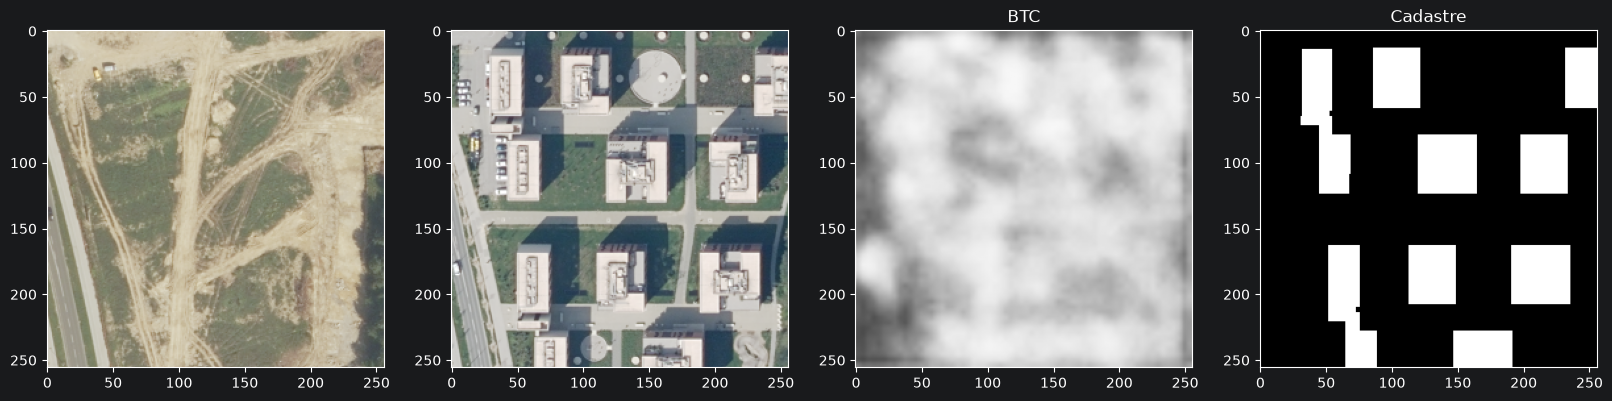

In [38]:
def detect(model, dataset, x0, y0, size):
    """Predicted change probability for"""
    sample = dataset[x0 : x0 + size, y0 : y0 + size]
    model = model.to(DEVICE).eval()
    with torch.no_grad():
        # image is (t, c, h, w) but model expects (b, t*c, h, w), pred is (1, 1, h, w)
        probability = model(sample['image'].flatten(0, 1)[None].to(DEVICE)).sigmoid()
    return sample, probability[0, 0].cpu()


sample, probability = detect(btc, pair, 458400, 100600, size=128)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(sample['image'][0].permute(1, 2, 0))
axes[1].imshow(sample['image'][1].permute(1, 2, 0))
axes[2].imshow(probability, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('BTC')
axes[3].imshow(sample['mask'][0], cmap='gray')
axes[3].set_title('Cadastre')

# Fine-tuning on our area

Levir-CD shows American areas, whic are again not exactly Slovenia. So we do a short fine-tuning on our data to adjust the model.

Since changes are rare, we will adjust our roi to sample more changed pixels and we do that by sampling around new buildings. We reduce the training roi to be limited to area of new buildings with some buffer.

In [33]:
# some helpers
def random_patches(dataset, roi, size, length=400):
    sampler = RandomPatchSampler(dataset, size=size, length=length, roi=roi)
    return DataLoader(dataset, sampler=sampler, batch_size=8)


# we will use these to sample patches near new buildings so our training data gets more changed pixels
new_buildings = gpd.read_file(PREPARED / 'labels/buildings_2024.gpkg').query('year > 2018')
def near_changes(roi, distance):
    """Limit given roi to some region around the new buidlings."""
    return roi & new_buildings.buffer(distance).union_all()

In [2]:
# TODO?
trainer = Trainer(max_epochs=3, logger=False, enable_checkpointing=False)
train_patches = random_patches(pair, near_changes(train_roi, 128), size=256)
trainer.fit(btc, train_patches, grid_patches(pair, val_roi, size=256))
trainer.test(btc, grid_patches(pair, test_roi, size=256))

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


NameError: name 'random_patches' is not defined

# Advanced S2 case

Orthotpohots are expensive and not updated so regularly. So while for buidlings this might work fine, some tasks require higher frequency of update.

Let's test now as a demo if we can still detect building changes in S2. For that we will need to demonstrate how to tinker with model to add a custom backbone (which is the main point of this final exercise).

In [39]:
from torchgeo.models import BTC

class DEOEncoder(nn.Module):
    """DEO's frozen Sentinel-2 encoder, in the shape BTC expects from its encoder."""

    def __init__(self):
        super().__init__()
        self.deo = deo_base(DEO_Weights.DEO_SWIN).requires_grad_(False)
        # DEO's Sentinel-2 statistics (https://github.com/wolfilip/DEO-FM); the published
        # transform has aerial RGB statistic
        transform = DEO_Weights.DEO_SWIN.transforms
        self.normalize = K.Normalize(
            mean=[1136.3, 1120.8, 1184.4, *transform.mean[3:]],
            std=[965.2, 712.1, 650.3, *transform.std[3:]],
        )

    def forward(self, x):
        features = self.deo.forward_features(self.normalize(x))
        return [f.permute(0, 3, 1, 2) for f in features]  # DEO is channels-last, despite the docstring lol


class DEOChange(BTC):
    """BTC with DEO's encoder instead of cityscapes"""

    def __init__(self):
        super().__init__(backbone='swin_base')  # same feature sizes as DEO
        self.encoder = DEOEncoder()

    def train(self, mode=True):
        super().train(mode)
        self.encoder.eval()
        return self

    def forward(self, x):
        # (batch, 2 dates x 10 bands, H, W) into (batch x 2 dates, 10 bands, H, W)
        ims = x.unflatten(1, (2, -1)).flatten(0, 1)
        feats = self.encoder(ims)
        difference = self.difference(feats)  # 2018 minus 2024, per scale
        # some upernet specific to work with custom enc
        uper_in = self.upernet_padding + difference
        change = self.final_layer(self.decoder(uper_in))
        return F.interpolate(change, size=x.shape[-2:], mode='bilinear')

In [40]:
# DEO's order
BANDS = ('B04', 'B03', 'B02', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B11', 'B12')

s2_before = Sentinel2(PREPARED / 's2/2018', bands=BANDS, crs=before.crs, res=10)
s2_after = Sentinel2(PREPARED / 's2/2024', bands=BANDS, crs=before.crs, res=10)
s2_change = Mask(PREPARED / 'labels/change_s2.tif', crs=before.crs, res=10)
s2_dates = IntersectionDataset(s2_before, s2_after, spatial_only=True)
s2_pair = IntersectionDataset(s2_dates, s2_change, transforms=as_pair)

In [41]:
deo = ChangeDetection(model='btc', backbone='swin_base', loss='bce', pos_weight=torch.tensor(30.0))
deo.model = DEOChange()

trainer = Trainer(max_epochs=10, logger=False, enable_checkpointing=False, fast_dev_run=False)
# 32 px Sentinel-2 patches cover 320 m, so they fit into our test strip.
train_patches = random_patches(s2_pair, near_changes(train_roi, 320), size=32)
trainer.fit(deo, train_patches, grid_patches(s2_pair, val_roi, size=32))
trainer.test(deo, grid_patches(s2_pair, test_roi, size=32))

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name          | Type              | Params | Mode  | FLOPs
--------------------------------------------------------------------
0 | model         | DEOChange         | 120 M  | train | 0    
1 | criterion     | BCEWithLogitsLoss | 0      | train | 0    
2 | train_metrics | MetricCollection  | 0      | train | 0    
3 | val_metrics   | MetricCollection  | 0      | train | 0    
4 | test_metrics  | MetricCollection  | 0      | train | 0    
--------------------------------------------------------------------
33.2 M    Trainable params
86.9 M    Non-trainable params
120 M     Total params
480.556   Total estimated model params size (MB)
451       Modules in train mode
0         Mo

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/opt/homebrew/Caskroom/miniforge/base/envs/tgeo/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/homebrew/Caskroom/miniforge/base/envs/tgeo/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

/opt/homebrew/Caskroom/miniforge/base/envs/tgeo/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


Text(0.5, 1.0, 'Cadastre')

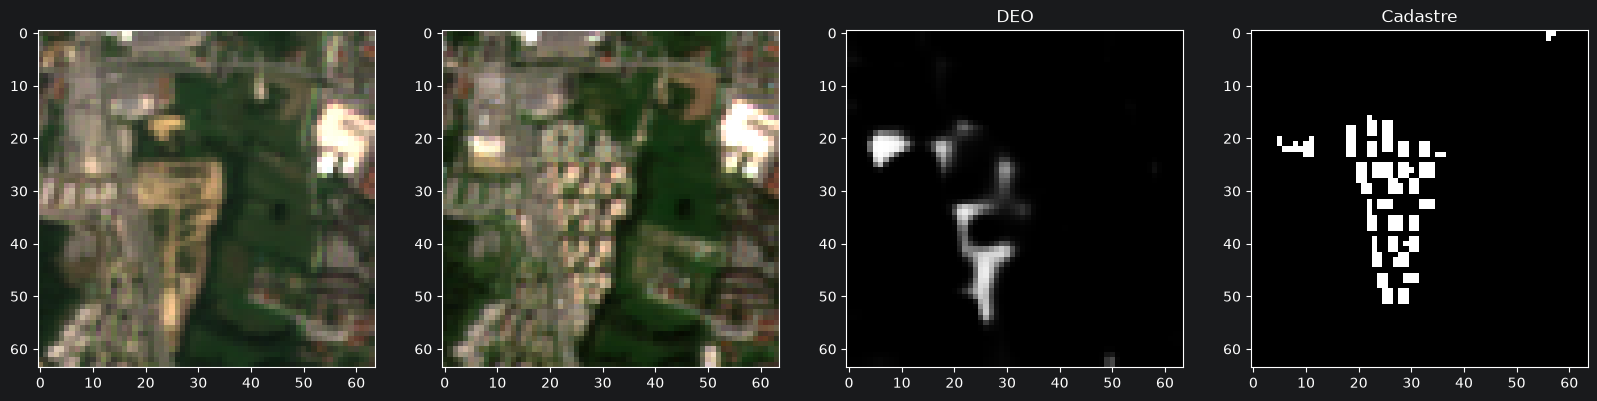

In [36]:
sample, probability = detect(deo, s2_pair, 458200, 100400, size=640)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow((sample['image'][0, :3] / 3000).clamp(0, 1).permute(1, 2, 0))
axes[1].imshow((sample['image'][1, :3] / 3000).clamp(0, 1).permute(1, 2, 0))
axes[2].imshow(probability, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('DEO')
axes[3].imshow(sample['mask'][0], cmap='gray', vmin=0, vmax=1)
axes[3].set_title('Cadastre')